In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [5]:
df = pd.read_csv("social_media_viral_content_dataset.csv")

df.head()

,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,views,likes,comments,shares,engagement_rate,sentiment_score,is_viral
0,SM_100000,Instagram,text,Sports,ur,UK,2024-12-10 00:00:00,#tech #funny #music,2319102,122058,15800,861,0.0598,0.464,1
1,SM_100001,Instagram,carousel,Sports,ur,Brazil,2024-10-13 00:00:00,#news #fyp #funny #ai #trending,2538464,110368,11289,54887,0.0695,-0.800,1
2,SM_100002,YouTube Shorts,video,Technology,ur,UK,2024-05-03 00:00:00,#ai #news,1051176,87598,47196,44132,0.1702,0.416,0
3,SM_100003,X,text,Politics,ur,US,2024-08-04 00:00:00,#ai #funny,5271440,329465,774,59736,0.0740,0.877,1
4,SM_100004,YouTube Shorts,text,Education,es,US,2024-03-28 00:00:00,#news #ai #viral #funny #fyp,3186256,199141,5316,83105,0.0903,0.223,1


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (2000, 15)

Column Names:
['post_id', 'platform', 'content_type', 'topic', 'language', 'region', 'post_datetime', 'hashtags', 'views', 'likes', 'comments', 'shares', 'engagement_rate', 'sentiment_score', 'is_viral']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          2000 non-null   str    
 1   platform         2000 non-null   str    
 2   content_type     2000 non-null   str    
 3   topic            2000 non-null   str    
 4   language         2000 non-null   str    
 5   region           2000 non-null   str    
 6   post_datetime    2000 non-null   str    
 7   hashtags         2000 non-null   str    
 8   views            2000 non-null   int64  
 9   likes            2000 non-null   int64  
 10  comments         2000 non-null   int64  
 11  shares           2000 non-null   int64  
 12  en

In [7]:
# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove rows with missing sentiment score or topic
df = df.dropna(subset=['sentiment_score', 'topic'])

print("\nCleaned Dataset Shape:", df.shape)

Missing Values:
post_id            0
platform           0
content_type       0
topic              0
language           0
region             0
post_datetime      0
hashtags           0
views              0
likes              0
comments           0
shares             0
engagement_rate    0
sentiment_score    0
is_viral           0
dtype: int64

Cleaned Dataset Shape: (2000, 15)


In [8]:
def classify_sentiment(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    else:
        return "Neutral"

df['sentiment'] = df['sentiment_score'].apply(classify_sentiment)

df[['topic', 'sentiment_score', 'sentiment']].head()

,topic,sentiment_score,sentiment
0,Sports,0.464,Positive
1,Sports,-0.800,Negative
2,Technology,0.416,Positive
3,Politics,0.877,Positive
4,Education,0.223,Positive


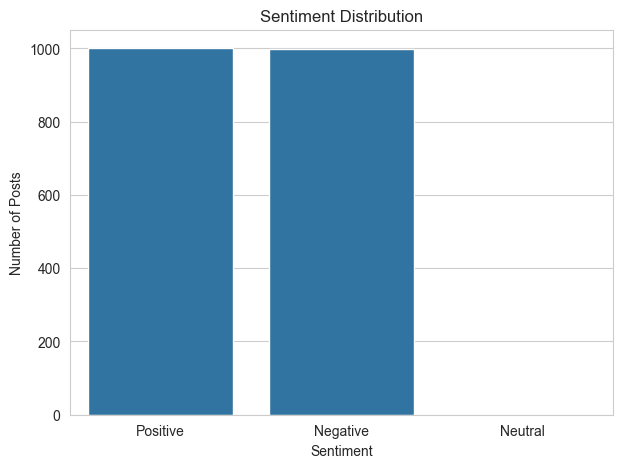

In [9]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='sentiment',
              order=['Positive', 'Negative', 'Neutral'])

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")

plt.show()

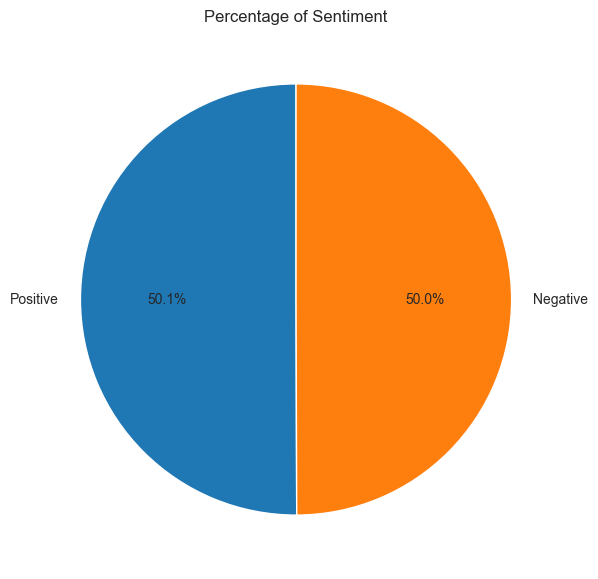

In [10]:
sentiment_counts = df['sentiment'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Percentage of Sentiment")

plt.show()

In [ ]:
topic_sentiment = pd.crosstab(
    df['topic'],
    df['sentiment']
)

print(topic_sentiment)

topic_sentiment.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("Topic-wise Sentiment Analysis")
plt.xlabel("Topics")
plt.ylabel("Number of Posts")

plt.xticks(rotation=45)
plt.legend(title="Sentiment")

plt.show()